In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

panel = pd.read_csv("../data/state_panel.csv")

# Count states at each stage; include stages with 0 states so the axis shows 0–5
stage_counts = panel["Stage_Final"].value_counts().sort_index()
stage_counts = stage_counts.reindex(range(6), fill_value=0)
stage_counts

Stage_Final
0     3
1     8
2     0
3    28
4    11
5     0
Name: count, dtype: int64

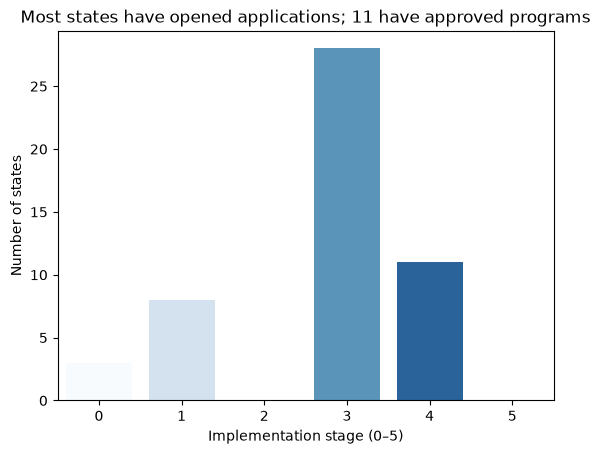

In [24]:
# Bar chart: one bar per stage, each stage a different color
ax = sns.barplot(
    x=stage_counts.index,
    y=stage_counts.values,
    hue=stage_counts.index,   # color bars by stage
    palette="Blues",          # light (early stage) → dark (later stage)
    legend=False              # x-axis already shows the stage, so no legend needed
)
ax.set_xlabel("Implementation stage (0–5)")
ax.set_ylabel("Number of states")
ax.set_title("Most states have opened applications; 11 have approved programs")
plt.show()

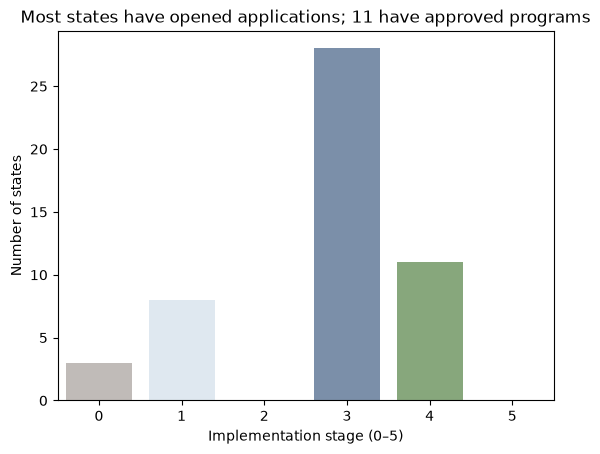

In [25]:
# Colors matched to the Tableau dashboard (sampled from screenshot)
stage_colors = {
    0: "#C1BAB7",  # Not yet reviewed / no activity — gray
    1: "#DCE8F3",  # Planning — very light blue (not yet used on the map)
    2: "#B6D0E7",  # Framework issued — light blue
    3: "#738EB1",  # Applications open — medium blue
    4: "#84AE75",  # Programs approved — green
    5: "#4F7F45",  # Student access — dark green (not yet used on the map)
}

ax = sns.barplot(x=stage_counts.index, y=stage_counts.values,
                 hue=stage_counts.index, palette=stage_colors, legend=False)
ax.set_xlabel("Implementation stage (0–5)")
ax.set_ylabel("Number of states")
ax.set_title("Most states have opened applications; 11 have approved programs")
plt.show()

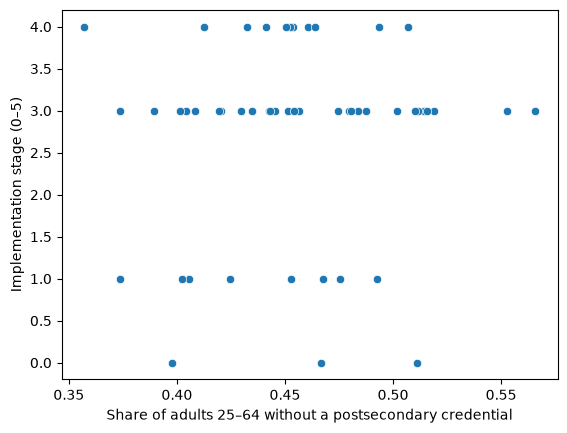

In [26]:
# Basic scatter: each dot is one state
ax = sns.scatterplot(data=panel, x="No_Credential_25_64", y="Stage_Final")
ax.set_xlabel("Share of adults 25–64 without a postsecondary credential")
ax.set_ylabel("Implementation stage (0–5)")
plt.show()

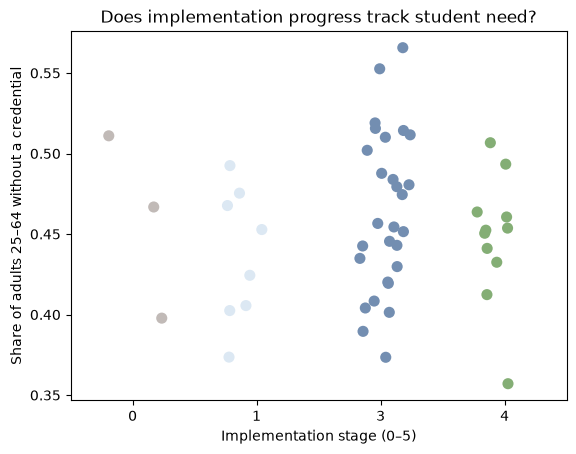

In [27]:
# Strip plot: stage on x, need on y; jitter spreads overlapping dots sideways
ax = sns.stripplot(
    data=panel,
    x="Stage_Final",
    y="No_Credential_25_64",
    hue="Stage_Final",
    palette=stage_colors,   # same colors as figure 1
    jitter=0.25,            # spread dots left/right so they don't overlap
    size=8,
    legend=False
)
ax.set_xlabel("Implementation stage (0–5)")
ax.set_ylabel("Share of adults 25–64 without a credential")
ax.set_title("Does implementation progress track student need?")
plt.show()

In [28]:
# Average and range of need by stage, plus number of states in each stage
panel.groupby("Stage_Final")["No_Credential_25_64"].agg(["count", "mean", "min", "max"]).round(3)

,count,mean,min,max
Stage_Final,,,,
0,3,0.459,0.398,0.511
1,8,0.437,0.374,0.492
3,28,0.463,0.374,0.566
4,11,0.448,0.357,0.507


**Finding (Figure 2):**   Implementation stage shows no clear relationship with student need.
Average shares of adults without a credential are similar across stages (43.7%–46.3%),
while variation *within* each stage is much larger (up to ~19 percentage points).
The two highest-need states, West Virginia (56.6%) and Nevada (55.3%), have opened
applications but have no approved programs yet. This pattern is descriptive only:
group sizes are small (Stage 0 has 3 states, Stage 1 has 8), and stages reflect data frozen on 2026-11-17.

In [29]:
# How many states in each capacity group?
panel["student_aid"].value_counts()

student_aid
0    26
1    24
Name: count, dtype: int64

In [30]:
# Counts: rows = capacity group, columns = stage; margins adds row/column totals
pd.crosstab(panel["student_aid"], panel["Stage_Final"], margins=True)

Stage_Final,0,1,3,4,All
student_aid,,,,,
0,3,6,13,4,26
1,0,2,15,7,24
All,3,8,28,11,50


In [31]:
# Shares within each group: each row adds up to 1
ct = pd.crosstab(panel["student_aid"], panel["Stage_Final"], normalize="index")
ct = ct.reindex(columns=range(6), fill_value=0)   # show all stages 0–5
ct.round(2)

Stage_Final,0,1,2,3,4,5
student_aid,,,,,,
0,0.12,0.23,0,0.50,0.15,0
1,0.00,0.08,0,0.62,0.29,0


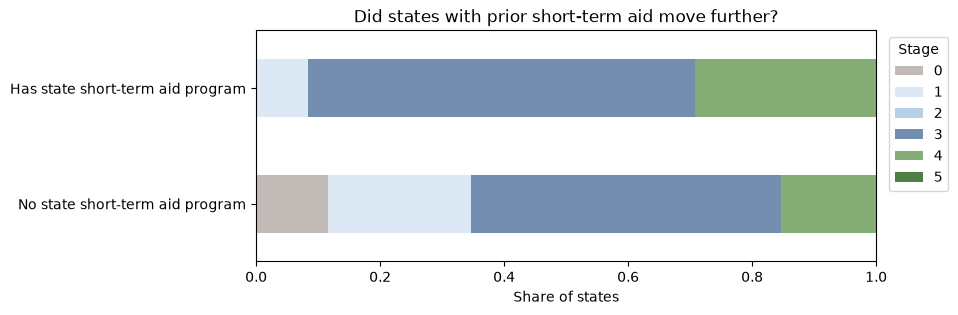

In [32]:
# Readable group names (if values are True/False, use {False: ..., True: ...} instead)
ct.index = ct.index.map({0: "No state short-term aid program", 1: "Has state short-term aid program"})

# One horizontal bar per group, split by stage, using the dashboard colors
ax = ct.plot(
    kind="barh",
    stacked=True,
    color=[stage_colors[s] for s in ct.columns],
    figsize=(8, 3)
)
ax.set_xlabel("Share of states")
ax.set_ylabel("")
ax.set_title("Did states with prior short-term aid move further?")
ax.legend(title="Stage", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

In [33]:
from scipy.stats import fisher_exact

# Outcome: did the state at least open applications? (Stage 3 or higher = 1, otherwise 0)
panel["opened_apps"] = (panel["Stage_Final"] >= 3).astype(int)

# 2x2 table: rows = capacity group (0/1), columns = opened applications (0/1)
table = pd.crosstab(panel["student_aid"], panel["opened_apps"])
table

opened_apps,0,1
student_aid,,
0,9,17
1,2,22


In [34]:
# Fisher's exact test on the 2x2 table
odds_ratio, p_value = fisher_exact(table)
print(f"Odds ratio: {odds_ratio:.2f}")
print(f"p-value: {p_value:.3f}")

Odds ratio: 5.82
p-value: 0.040


In [35]:
# Outcome 2: does the state have at least one approved program? (Stage 4 or higher)
panel["has_approval"] = (panel["Stage_Final"] >= 4).astype(int)
table2 = pd.crosstab(panel["student_aid"], panel["has_approval"])
odds_ratio2, p_value2 = fisher_exact(table2)
print(table2)
print(f"Odds ratio: {odds_ratio2:.2f}, p-value: {p_value2:.3f}")

has_approval   0  1
student_aid        
0             22  4
1             17  7
Odds ratio: 2.26, p-value: 0.314


**Finding (Figure 3):** States with a pre-existing state short-term student aid program
moved further in early implementation. 92% of them (22 of 24) had at least opened applications,
compared with 65% (17 of 26) of states without such a program (Fisher's exact test, p = 0.04).
The difference at the approval stage is smaller and not statistically distinguishable
(29% vs 15% with approved programs; p = 0.31). These are descriptive associations,
not causal effects; capacity may also reflect other state differences such as administrative
resources or prior workforce policy attention.

### Conclusion
Taken together, the three figures suggest that early Workforce Pell implementation reflects
**capacity more than need**. States with existing short-term credential infrastructure were quicker
to open application processes, while states where more adults lack credentials are not moving faster.
If this pattern persists, the program's benefits may reach lower-need states first, which runs against
its goal of expanding access. This is a pattern to monitor, not a causal conclusion.

### Limitations
- **Descriptive, not causal.** Capacity may stand in for other state differences, such as administrative
  resources, state size, or prior attention to workforce policy.
- **Small numbers.** With 50 states, moving one or two states changes group percentages noticeably.
- **Exploratory tests.** The Stage 3 and Stage 4 thresholds were chosen after inspecting the data.
  Both tests are reported, and p-values should be read as exploratory.
- **Early snapshot.** Many states have decisions scheduled for late 2026 and early 2027.
- **Uneven verification.** Stages for about 23 states rely on third-party implementation trackers
  rather than official state sources.
- **Measure timing.** The capacity measure predates Workforce Pell (2024) and may miss newer programs.

### Next steps
- Robustness check: repeat Figure 3 using any state short-term initiative, and excluding the four
  states whose programs only partially fit HCM's short-term definition (AR, KY, MN, NV).
- Update the analysis after the next round of state decisions in early 2027.

In [36]:
# Robustness check
from scipy.stats import fisher_exact

def capacity_tests(df, group_col):
    """Run Fisher's exact tests comparing capacity groups on two outcomes."""
    results = []
    for outcome, threshold in [("Opened applications (Stage ≥ 3)", 3),
                               ("Approved programs (Stage ≥ 4)", 4)]:
        reached = (df["Stage_Final"] >= threshold).astype(int)    # 1 if state reached this stage
        table = pd.crosstab(df[group_col], reached)                # 2x2 table
        odds_ratio, p_value = fisher_exact(table)
        share = reached.groupby(df[group_col]).mean()              # share reaching stage, by group
        results.append({
            "Capacity measure": group_col,
            "States": len(df),
            "Outcome": outcome,
            "Share, capacity = 1": round(share.get(1, 0), 2),
            "Share, capacity = 0": round(share.get(0, 0), 2),
            "Odds ratio": round(odds_ratio, 2),
            "p-value": round(p_value, 3),
        })
    return pd.DataFrame(results)

In [37]:
# Main: student aid programs (all 50 states)
main = capacity_tests(panel, "student_aid")

# Robustness A: any state short-term initiative, not only student aid
rob_a = capacity_tests(panel, "any_initiative")

# Robustness B: student aid, excluding 4 states whose programs only partially fit the definition
partial_fit = ["AR", "KY", "MN", "NV"]
panel_b = panel[~panel["State_Code"].isin(partial_fit)]
rob_b = capacity_tests(panel_b, "student_aid")
rob_b["Capacity measure"] = "student_aid (excl. AR, KY, MN, NV)"

# Put all results in one table
robustness = pd.concat([main, rob_a, rob_b], ignore_index=True)
robustness

,Capacity measure,States,Outcome,"Share, capacity = 1","Share, capacity = 0",Odds ratio,p-value
0,student_aid,50,Opened applications (Stage ≥ 3),0.92,0.65,5.82,0.040
1,student_aid,50,Approved programs (Stage ≥ 4),0.29,0.15,2.26,0.314
2,any_initiative,50,Opened applications (Stage ≥ 3),0.81,0.72,1.67,0.494
3,any_initiative,50,Approved programs (Stage ≥ 4),0.25,0.17,1.67,0.724
4,"student_aid (excl. AR, KY, MN, NV)",46,Opened applications (Stage ≥ 3),0.90,0.65,4.76,0.082
5,"student_aid (excl. AR, KY, MN, NV)",46,Approved programs (Stage ≥ 4),0.35,0.15,2.96,0.169


### Robustness checks

To test whether the Figure 3 pattern depends on how "capacity" is defined, the Fisher's exact tests
were repeated under two alternative definitions.

**Excluding partial-fit states (AR, KY, MN, NV): direction holds, precision drops.**
The gap is nearly unchanged (90% vs. 65% opened applications, compared with 92% vs. 65% in the main
version), and the odds ratio stays similar (4.76 vs. 5.82). The p-value rises from 0.04 to 0.08,
mainly because four fewer states make the comparison less precise. The direction is consistent,
but precision is limited.

**Any state short-term initiative: the gap largely disappears.**
Using a broader definition of capacity, 81% vs. 72% of states had opened applications (p = 0.49).
When capacity is defined broadly, no meaningful difference remains.

**Approved programs (Stage ≥ 4): no version is statistically distinguishable.**
This matches the main result: differences at the approval stage are not yet detectable under any
definition.

**Interpretation.**
Read together with the main result, these checks suggest that what matters may not be whether a state
had *any* short-term credential effort, but whether it *directly funded students* in short-term programs.
One plausible explanation is that states with student aid programs already had processes for deciding
which programs qualify and which students can receive funds, which closely resemble Workforce Pell's
approval steps, so they could set up application processes faster. "Any initiative" also includes
institutional capacity-building grants and outcomes-based funding, which are less related to program
approval.

**Caveat.** This explanation was proposed *after* seeing the results. It should be treated as a
hypothesis to test, not as a finding.

In [38]:
uv add plotly kaleido

/Users/emmawang/Desktop/maidong/workforce-pell-state-tracker/.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


In [39]:
import plotly.express as px

# Stage labels for the legend, in order
stage_labels = {0: "0 Not yet reviewed / no activity", 1: "1 Planning", 2: "2 Framework issued",
                3: "3 Applications open", 4: "4 Programs approved", 5: "5 Student access"}
panel["Stage_Label"] = panel["Stage_Final"].map(stage_labels)

# Same colors as the other figures, keyed by label
label_colors = {stage_labels[s]: c for s, c in stage_colors.items()}

fig = px.choropleth(
    panel,
    locations="State_Code",           # two-letter state codes
    locationmode="USA-states",        # tell plotly these are US state codes
    color="Stage_Label",              # color states by stage
    color_discrete_map=label_colors,  # use our stage colors
    category_orders={"Stage_Label": list(stage_labels.values())},  # legend in stage order
    scope="usa",                      # show the US only
    hover_name="State",               # show state name on hover
    title="Workforce Pell implementation stage by state (as of 2026-11-17)"
)

import plotly.graph_objects as go

# Stages present in the data (plotly only draws legend items for these)
shown = set(panel["Stage_Label"])

# Add an empty legend item for each stage with no states, e.g., Stage 2
for stage, label in stage_labels.items():
    if label not in shown:
        fig.add_trace(go.Scattergeo(
            lat=[None], lon=[None],          # no point on the map, legend only
            mode="markers",
            marker=dict(symbol="square", size=12, color=stage_colors[stage]),
            name=label,
            legendrank=stage,                # place it in stage order
        ))

# Put the existing legend items in stage order too
for trace in fig.data:
    for stage, label in stage_labels.items():
        if trace.name == label:
            trace.legendrank = stage
            
fig.show()
fig.write_image("../figures/fig4_stage_map.png", width=1000, height=600, scale=2)

In [40]:
import os
from matplotlib.ticker import PercentFormatter

os.makedirs("../figures", exist_ok=True)   # create the figures folder if it doesn't exist

SOURCE = "Source: Workforce Pell State Tracker (author), stages verified through 2026-11-17."
short_labels = {0: "0\nNo activity /\nnot reviewed", 1: "1\nPlanning", 2: "2\nFramework\nissued",
                3: "3\nApplications\nopen", 4: "4\nPrograms\napproved", 5: "5\nStudent\naccess"}

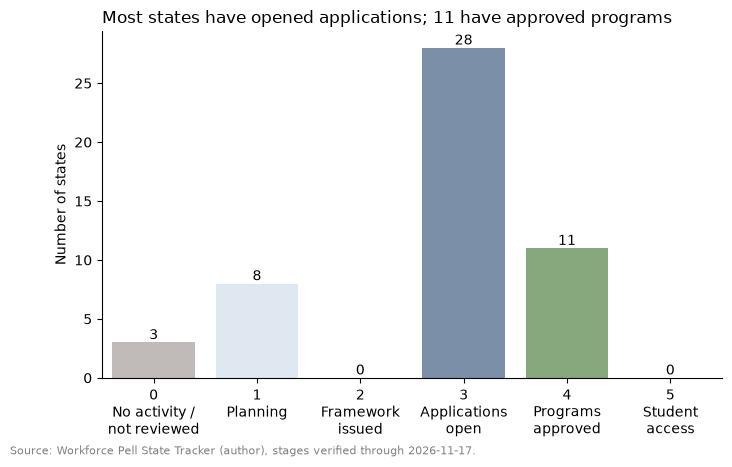

In [41]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=stage_counts.index, y=stage_counts.values,
            hue=stage_counts.index, palette=stage_colors, legend=False, ax=ax)

for bars in ax.containers:                 # one container per color group
    ax.bar_label(bars, fmt="%d")           # number on top of each bar

ax.set_xticks(range(6))
ax.set_xticklabels([short_labels[s] for s in range(6)])
ax.set_xlabel("")
ax.set_ylabel("Number of states")
ax.set_title("Most states have opened applications; 11 have approved programs", loc="left")
sns.despine()                               # remove top and right borders
fig.text(0.01, -0.06, SOURCE, fontsize=8, color="gray")

fig.savefig("../figures/fig1_stage_counts.png", dpi=200, bbox_inches="tight")
plt.show()

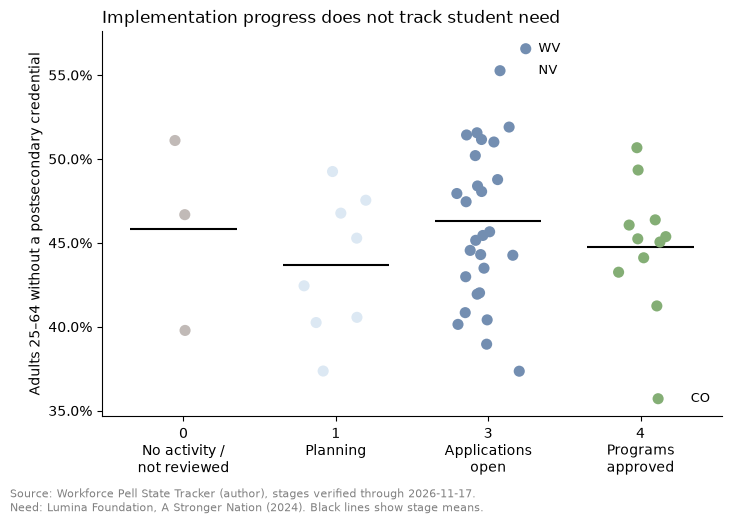

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(data=panel, x="Stage_Final", y="No_Credential_25_64",
              hue="Stage_Final", palette=stage_colors, jitter=0.25, size=8, legend=False, ax=ax)

# Black line = mean need within each stage
stages_present = sorted(panel["Stage_Final"].unique())
means = panel.groupby("Stage_Final")["No_Credential_25_64"].mean()
for i, s in enumerate(stages_present):
    ax.hlines(means[s], i - 0.35, i + 0.35, color="black", linewidth=1.5)

# Label the states discussed in the text
for code in ["WV", "NV", "CO"]:
    row = panel[panel["State_Code"] == code].iloc[0]
    i = stages_present.index(row["Stage_Final"])
    ax.text(i + 0.33, row["No_Credential_25_64"], code, va="center", fontsize=9)

ax.set_xticks(range(len(stages_present)))
ax.set_xticklabels([short_labels[s] for s in stages_present])
ax.set_xlabel("")
ax.set_ylabel("Adults 25–64 without a postsecondary credential")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Implementation progress does not track student need", loc="left")
sns.despine()
fig.text(0.01, -0.08, SOURCE + "\nNeed: Lumina Foundation, A Stronger Nation (2024). Black lines show stage means.",
         fontsize=8, color="gray")

fig.savefig("../figures/fig2_need_vs_stage.png", dpi=200, bbox_inches="tight")
plt.show()

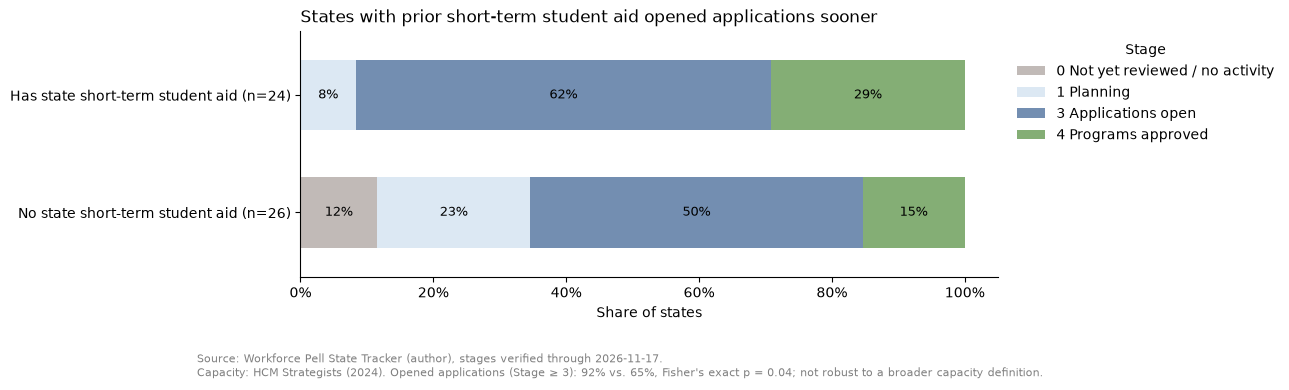

In [43]:
ct_plot = ct.loc[:, ct.sum() > 0]   # drop stages with no states (2 and 5)
ct_plot.index = ["No state short-term student aid (n=26)", "Has state short-term student aid (n=24)"]

fig, ax = plt.subplots(figsize=(9, 3.2))
ct_plot.plot(kind="barh", stacked=True, width=0.6, ax=ax,
             color=[stage_colors[s] for s in ct_plot.columns])

for bars in ax.containers:   # percentage inside each segment (skip tiny ones)
    ax.bar_label(bars, labels=[f"{v:.0%}" if v >= 0.08 else "" for v in bars.datavalues],
                 label_type="center", fontsize=9)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, [stage_labels[s] for s in ct_plot.columns], title="Stage",
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of states")
ax.set_ylabel("")
ax.set_title("States with prior short-term student aid opened applications sooner", loc="left")
sns.despine()
fig.text(0.01, -0.2, SOURCE + "\nCapacity: HCM Strategists (2024). Opened applications (Stage ≥ 3): 92% vs. 65%, "
         "Fisher's exact p = 0.04; not robust to a broader capacity definition.", fontsize=8, color="gray")

fig.savefig("../figures/fig3_capacity_vs_stage.png", dpi=200, bbox_inches="tight")
plt.show()

### Key takeaways

- **Figure 1:** By mid-November 2026, 39 of 50 states had opened Workforce Pell applications, but only 11 had approved a program and none had confirmed student access.
- **Figure 2:** Average need is nearly identical across implementation stages; the two highest-need states, West Virginia and Nevada, have no approved programs yet.
- **Figure 3:** States that already funded short-term credential students were more likely to have opened applications (92% vs. 65%), though the pattern weakens under broader definitions of capacity.
- **Figure 4 (map):** Implementation stages by state, as of November 17, 2026.